<a href="https://colab.research.google.com/github/Bhumiii27/ML-Labs/blob/main/Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K-Means Clusteringg

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
##KMeans Clustering

In [19]:
df1 = pd.read_csv('/content/KMeans.csv')
X = df1.to_numpy(dtype=float)

In [20]:
X = np.array(df1)

In [21]:
import random
init_centroids = random.sample(range(0, len(df1)), 3)
init_centroids

[147, 1, 162]

In [22]:
centroids = []
for i in init_centroids:
    centroids.append(df1.loc[i])
centroids

[Age                       32
 Annual Income (k$)        77
 Spending Score (1-100)    74
 Name: 147, dtype: int64,
 Age                       21
 Annual Income (k$)        15
 Spending Score (1-100)    81
 Name: 1, dtype: int64,
 Age                       19
 Annual Income (k$)        81
 Spending Score (1-100)     5
 Name: 162, dtype: int64]

In [23]:
centroids = np.array(centroids)
centroids

array([[32, 77, 74],
       [21, 15, 81],
       [19, 81,  5]])

In [24]:
def calc_distance(X1, X2):
    return(sum((X1 - X2)**2))**0.5

In [25]:
def findClosestCentroids(ic, X):
    assigned_centroid = []
    for i in X:
        distance=[]
        for j in ic:
            distance.append(calc_distance(i, j))
        assigned_centroid.append(np.argmin(distance))
    return assigned_centroid

In [26]:
print(X[:5])
print(centroids)
print(X.dtype, centroids.dtype)

[[19 15 39]
 [21 15 81]
 [20 16  6]
 [23 16 77]
 [31 17 40]]
[[32 77 74]
 [21 15 81]
 [19 81  5]]
int64 int64


In [27]:
get_centroids = findClosestCentroids(centroids, X)
print(get_centroids)

[np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(2), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)

In [28]:
def calc_centroids(clusters, X):
    new_centroids = []
    new_df = pd.concat([pd.DataFrame(X), pd.DataFrame(clusters, columns=['cluster'])],
                      axis=1)
    for c in set(new_df['cluster']):
        current_cluster = new_df[new_df['cluster'] == c][new_df.columns[:-1]]
        cluster_mean = current_cluster.mean(axis=0)
        new_centroids.append(cluster_mean)
    return new_centroids

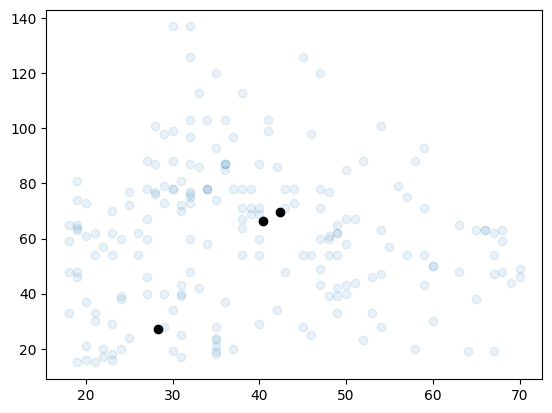

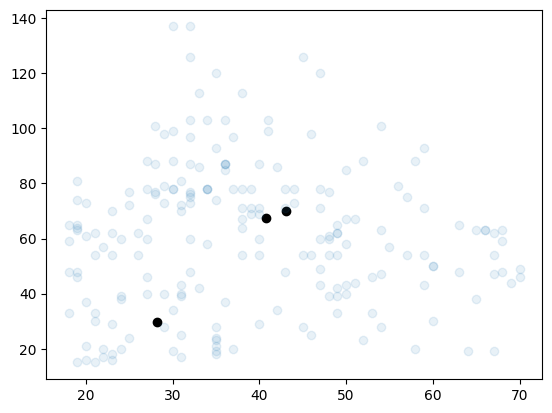

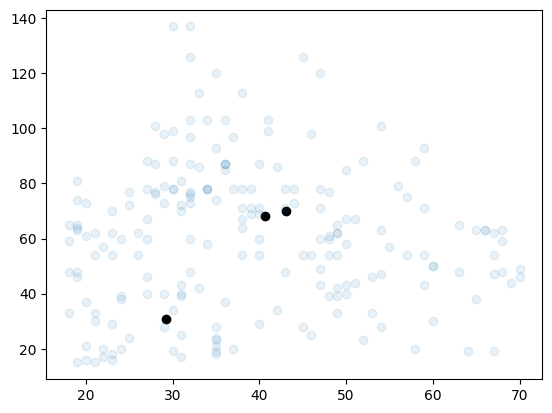

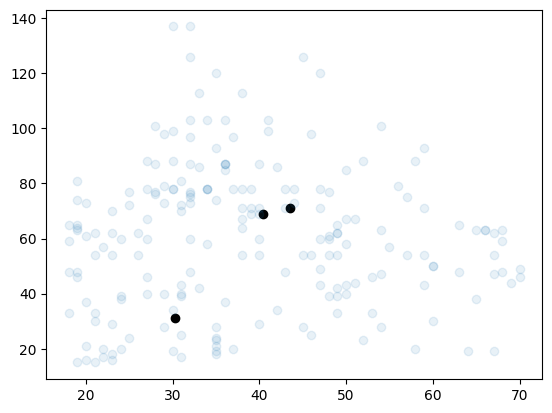

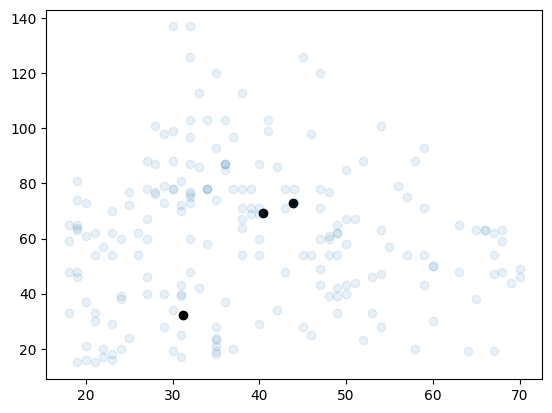

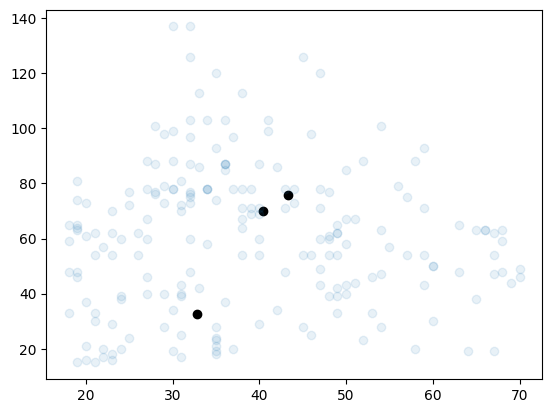

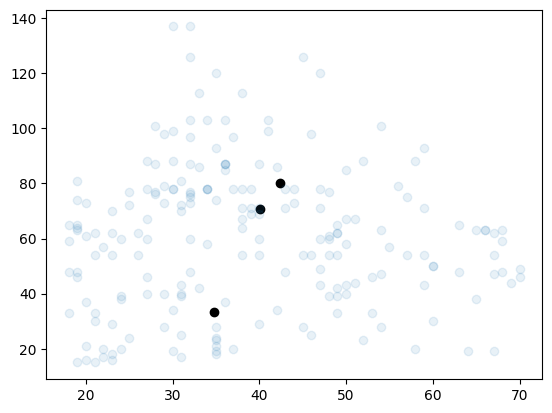

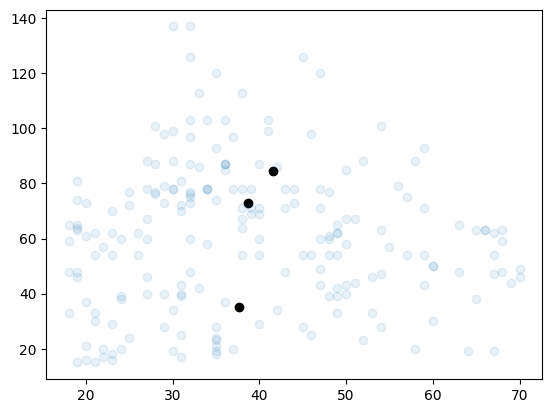

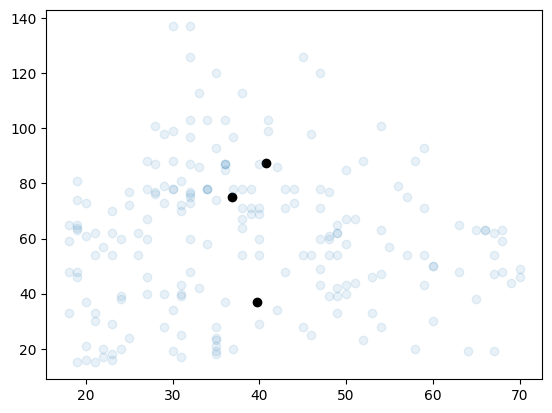

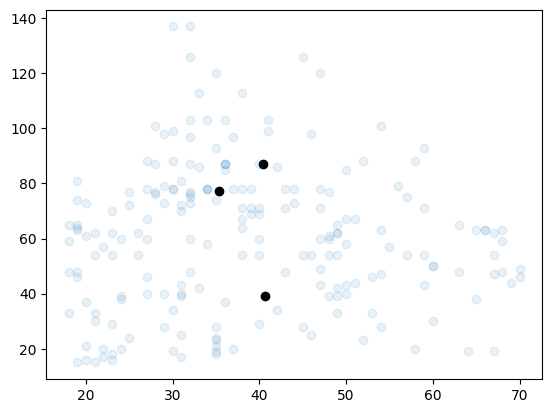

In [29]:
for i in range(10):
    get_centroids = findClosestCentroids(centroids, X)
    centroids = calc_centroids(get_centroids, X)
    #print(centroids)
    plt.figure()
    plt.scatter(np.array(centroids)[:, 0], np.array(centroids)[:, 1], color='black')
    plt.scatter(X[:, 0], X[:, 1], alpha=0.1)
    plt.show()

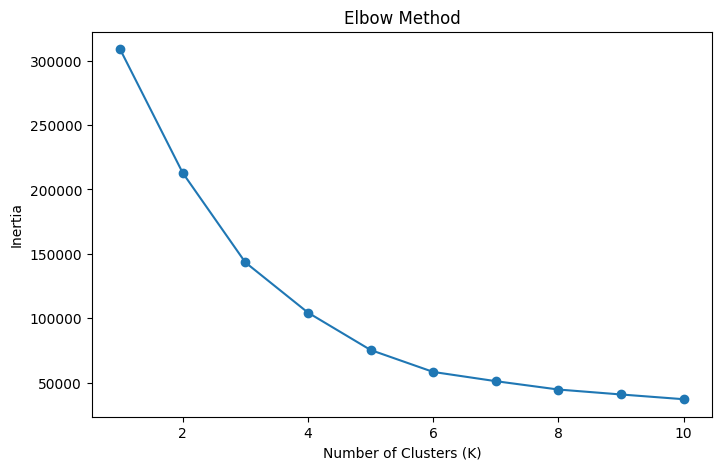

In [33]:
# Plot Elbow Curve
from sklearn.cluster import KMeans

K = range(1, 11)
inertia = []

for i in K:
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()